# Backtest a previously completed geo test without an existing GeoX design file

**Goal:** address [issue #13](https://github.com/google/meridian-geox/issues/13)

Use this notebook to onboard and backtest completed tests on the GeoX engine; treat lift/p-value as the primary inference, design MDE as a planning benchmark, and corrected spend-based metrics as finance-facing—after you configure panel spend and geo variants to match reality.

**Steps:**

1. Install + imports (minimal warnings)

2. Define experiment metadata (geos, dates, type, methodology, optional budget)

3. Load panel (example geox CSV | your CSV upload)

4. Validate + format panel (filter geos, variant, Status)

5. Reconstruct Design + AnalysisConfig → analyze() ← core

6. Scorecard + corrected efficiency + TBR proxy + plots

7. (Optional) run_design on pre-period + compare MDE to observed lift

8. Limitations & FAQ

In [ ]:
# Install meridian-geox: from PyPI @ latest release
!pip install --upgrade meridian-geox

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 535.0/535.0 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.7/401.7 kB 14.4 MB/s eta 0:00:00


In [ ]:
import datetime
import pprint
import warnings
from IPython.display import display
import meridian_geox as geox
from meridian_geox import api as geox_api
import meridian_geox.design as geox_design
import pandas as pd
import numpy as np

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings(
    "ignore",
    message="invalid value encountered in divide",
    category=RuntimeWarning,
)

pd.set_option("display.max_columns", None)

meridian_geox_root = None

In [ ]:
# If you prefer to save the design in Google Drive, run this cell.
import os
from google.colab import drive

drive_mount = '/content/drive'
drive.mount(drive_mount, force_remount=True)

# Optional: specify a subfolder to organize your runs
subfolder = 'geox_test'  # @param {"type":"string", "placeholder": "e.g., my_geox_project"}

# Define the root path specifically for GeoX designs and reports
meridian_geox_root = f'{drive_mount}/MyDrive/{subfolder}'

# Create the directory if it doesn't exist
if not os.path.exists(meridian_geox_root):
  os.makedirs(meridian_geox_root)
  print(f'Created directory: {meridian_geox_root}')
else:
  print(f'Using directory: {meridian_geox_root}')


Mounted at /content/drive
Using directory: /content/drive/MyDrive/geox_test


# Experiments to Backtest

In [ ]:
#@title Dictionary of past experiment designs

past_experiments = {
    'channel_x_test': {
      "minimum_detectable_effect":0.0,
      "design_implied_cpic":0.0,
      "p_value":1.0,
      # "budget":0.0,
      "budget":150000.0,
      "analysis_start_date":pd.to_datetime("2020-03-15"),
      "analysis_end_date":pd.to_datetime("2020-03-31"),
      "treatment_geos": {'145', '152', '83', '97', '64', '66', '119', '120', '161', '168', '169', '133', '189', '146', '174', '75', '18', '110', '72', '192', '92', '115', '27', '149', '80', '31', '122', '51', '135', '11', '46', '139', '49', '128', '173', '28', '90', '23', '20', '151', '84', '172', '25', '157', '35', '190', '159', '127', '26', '163', '44', '123', '55', '175', '3', '96', '10'},
      "control_geos": {'198', '45', '131', '8', '144', '22', '155', '93', '68', '74', '177', '181', '142', '59', '193', '39', '19', '88', '188', '196', '15', '63', '197', '89', '41', '108', '125', '52', '95', '33', '5', '77', '111', '138', '38', '42', '103', '195', '126', '57', '71', '73', '118', '105', '184', '81', '164', '171', '136', '69', '98', '141', '166', '180', '61', '183', '36'},
      "experiment_type":geox_api.ExperimentType.HEAVY_UP, # Adjust to HEAVY_UP, GO_DARK or HOLDBACK if applicable
      "methodology":geox_api.Methodology.TBR # Adjust to ...
    },
    'channel_y_test':{}   # add in additional experiments to backtest

}

In [ ]:
#@title single-cell dummy data
# Load the design data
analysis_data = pd.read_csv(
    "https://raw.githubusercontent.com/google/meridian-geox/refs/heads/main/meridian_geox/data/example_design_data_single_cell.csv"
)

analysis_data['location'] = analysis_data['location'].astype(str)
analysis_data['date'] = pd.to_datetime(analysis_data['date'])
analysis_data['conversions'] = analysis_data['conversions'].astype(float)

analysis_data

,date,location,conversions,spend
0,2020-01-01,10,1217.186754,13.961282
1,2020-01-01,103,478.754850,5.360183
2,2020-01-01,105,1077.686355,11.070354
3,2020-01-01,108,347.516532,4.956830
4,2020-01-01,11,914.836202,10.872813
...,...,...,...,...
10369,2020-03-31,93,373.519981,4.097063
10370,2020-03-31,95,300.988910,3.824511
10371,2020-03-31,96,1143.360919,13.277282
10372,2020-03-31,97,374.899741,4.845652


In [ ]:
#@title define experiment to backtest
experiment_name = 'channel_x_test'
experiment = past_experiments[experiment_name]

In [ ]:
#@title format analysis_data based on dictionary records

experiment_geos = experiment["treatment_geos"] | experiment["control_geos"]
analysis_data = analysis_data[analysis_data["location"].isin(experiment_geos)]

analysis_data['variant_name'] = analysis_data['location'].apply(
    lambda loc: 'treatment' if loc in experiment['treatment_geos'] else 'control'
)

# helper column for clarity
analysis_data['Status'] = np.where(
    analysis_data['date'] < experiment['analysis_start_date'],
    'Pre-test (Baseline)',
    'Experiment Live'
)

analysis_data = analysis_data[[
    'date', 'location', 'variant_name', 'conversions', 'spend', 'Status'
]].copy()


# Display the formatted data's stats
display(analysis_data)
display(analysis_data['Status'].value_counts())
display(analysis_data['variant_name'].value_counts())
display(analysis_data.groupby('variant_name')[['spend','conversions']].mean())

,date,location,variant_name,conversions,spend,Status
0,2020-01-01,10,treatment,1217.186754,13.961282,Pre-test (Baseline)
1,2020-01-01,103,control,478.754850,5.360183,Pre-test (Baseline)
2,2020-01-01,105,control,1077.686355,11.070354,Pre-test (Baseline)
3,2020-01-01,108,control,347.516532,4.956830,Pre-test (Baseline)
4,2020-01-01,11,treatment,914.836202,10.872813,Pre-test (Baseline)
...,...,...,...,...,...,...
10369,2020-03-31,93,control,373.519981,4.097063,Experiment Live
10370,2020-03-31,95,control,300.988910,3.824511,Experiment Live
10371,2020-03-31,96,treatment,1143.360919,13.277282,Experiment Live
10372,2020-03-31,97,treatment,374.899741,4.845652,Experiment Live


,count
Status,
Pre-test (Baseline),8436
Experiment Live,1938


,count
variant_name,
treatment,5187
control,5187


,spend,conversions
variant_name,,
control,6.123494,525.589238
treatment,6.397602,545.390445


# Design Configuration for Backtest

In [ ]:
experiment_length = (experiment['analysis_end_date'] - experiment['analysis_start_date']).days
print(f"Experiment length: {experiment_length} days")

historical_cell = geox_api.PerCellDesign(
    treatment_geos=experiment['treatment_geos'],
    minimum_detectable_effect=0.0,
    design_implied_cpic=0.0,
    p_value=1.0,
    # budget=0.0
    budget=experiment['budget']
)

# Define the missing Design Config
my_design_config = geox_api.DesignConfig(
    experiment_duration=datetime.timedelta(days=experiment_length),
    experiment_types=experiment['experiment_type'],
    methodology=experiment['methodology']
)

# Create a pre-sorted 1D array of stratum labels aligning with sorted unique geos
total_experiment_geos = len(experiment['treatment_geos']) + len(experiment['control_geos'])
dummy_stratum_labels_array = np.ones(total_experiment_geos, dtype=np.int32)

# Construct the overarching Design object
my_backtest_design = geox_api.Design(
    designs={"cell_1": historical_cell},
    control_geos=experiment['control_geos'],
    excluded_geos=set(),
    design_config=my_design_config,
    data=analysis_data,
    geo_stratum_labels=dummy_stratum_labels_array
)

# Pass your custom design into the Analysis Config
analysis_config = geox_api.AnalysisConfig(
    design=my_backtest_design,
    analysis_start_date=experiment['analysis_start_date'],
    analysis_end_date=experiment['analysis_end_date']
)

# Run the analysis on your pretest and test data with the placeholder MDE/p-value/budget on PerCellDesign
analysis_result = geox.analyze(analysis_data, analysis_config)

Experiment length: 16 days


# Backtest Design

In [ ]:
#@title run design
# actual_channel_test_spend = 100000  #@param

# Isolate the pre-test data window (e.g., 12 weeks before intervention)
pretest_data = analysis_data[analysis_data['date'] < experiment['analysis_start_date']].copy()

# Build Constraints containing your corrected channel spend and geo groups
analysis_constraints = geox_api.Constraints(
    # budget=actual_channel_test_spend,  # Corrected channel spend
    budget=experiment['budget'],
    treatment_geos=experiment['treatment_geos'],
    control_geos=experiment['control_geos']
)

# Run the native design pipeline
design_set = geox_design.run_design(
    data=pretest_data,
    design_config=my_design_config,
    constraints=analysis_constraints
)


In [ ]:
pprint.pprint(design_set)

DesignSet(designs={'25fb48d2-2d0e-4dee-8402-fbc507167fa4': Design(designs={'cell_1': PerCellDesign(treatment_geos={'103',
                                                                                                                   '105',
                                                                                                                   '110',
                                                                                                                   '115',
                                                                                                                   '119',
                                                                                                                   '131',
                                                                                                                   '136',
                                                                                                                   '141',
                        

# Backtest Analysis

In [ ]:
#@title summarize the results

# Print the dictionary mapping cell names to AnalysisMetrics objects
pprint.pprint(analysis_result.results)

{'cell_1': AnalysisMetrics(lift=Estimate(point_estimate=1840.6435546875,
                                         lower_bound=-2514.1064453125,
                                         upper_bound=7243.7685546875,
                                         standard_deviation=2968.948486328125,
                                         p_value=0.4411177635192871),
                           percent_lift=Estimate(point_estimate=0.003489255905151367,
                                                 lower_bound=-0.004795730113983154,
                                                 upper_bound=0.013859391212463379,
                                                 standard_deviation=0.005656844936311245,
                                                 p_value=0.4411177635192871),
                           icpd=Estimate(point_estimate=339.9143981933594,
                                         lower_bound=-464.2837829589844,
                                         upper_bound=1337.7175292968

In [ ]:
#@title extract metrics

# Isolate the metrics object for your specific test cell
cell_1_metrics = analysis_result.results['cell_1']

# Extract the numerical values from the nested 'Estimate' objects
lift = cell_1_metrics.lift.point_estimate
ci_lower = cell_1_metrics.lift.lower_bound
ci_upper = cell_1_metrics.lift.upper_bound
p_value = cell_1_metrics.lift.p_value

percent_lift = cell_1_metrics.percent_lift.point_estimate
icpd = cell_1_metrics.icpd.point_estimate

# Calculate implied spend (Since iCPD = Lift / Spend, Spend = Lift / iCPD)
total_test_spend = lift / icpd

# Calculate iROAS manually (assuming your KPI was conversions, not revenue)
aov = 370.00 #@param
iroas = (lift * aov) / total_test_spend

print(f"--- Campaign Scorecard ---")
print(f"Incremental Lift: {lift:,.0f} (CI: {ci_lower:,.0f} to {ci_upper:,.0f})")
print(f"Percent Lift:     {percent_lift:.2%}")
print(f"P-Value:          {p_value:.3f}")
print(f"iCPD:             {icpd:.4f} conversions per dollar")
print(f"iROAS:            {iroas:.2f}x")

--- Campaign Scorecard ---
Incremental Lift: 1,841 (CI: -2,514 to 7,244)
Percent Lift:     0.35%
P-Value:          0.441
iCPD:             339.9144 conversions per dollar
iROAS:            125768.33x


In [ ]:
#@title extract metrics based on actual intervention spend
# Isolate test-window spend across treatment DMAs
# (or scale national spend by treatment DMA impression/population share)
# actual_channel_test_spend = 150000  #@param
actual_channel_test_spend = experiment['budget']
aov = 370.00  #@param

# Extract incremental lift from existing result
lift = cell_1_metrics.lift.point_estimate  # 5,946.78 conversions

# Compute true efficiency metrics
corrected_icpd = lift / actual_channel_test_spend   # conversions per dollar (aligned with GeoX)
corrected_cpic = actual_channel_test_spend / lift # $ per incremental conversion
true_iroas = (lift * aov) / actual_channel_test_spend

print(f"--- Corrected efficiency (actual media spend) ---")
print(f"Actual Channel Spend:                ${actual_channel_test_spend:,.2f}")
print(f"Corrected Conversion per Dollar:     {corrected_icpd:.4f} conversions per dollar")
print(f"Corrected Cost per Conversion:       ${corrected_cpic:,.2f} per conversion")
print(f"Corrected iROAS:                     {true_iroas:.2f}x")


--- Corrected efficiency (actual media spend) ---
Actual Channel Spend:                $150,000.00
Corrected Conversion per Dollar:     0.0123 conversions per dollar
Corrected Cost per Conversion:       $81.49 per conversion
Corrected iROAS:                     4.54x


In [ ]:
#@title evaluate TBR model fit
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error

# Isolate the pre-test period
# Adjust the date to match the day before your experiment actually launched
pre_test_data = analysis_data[analysis_data['date'] < experiment['analysis_start_date']]

# Aggregate conversions by day for both groups
treatment_geos = list(experiment['treatment_geos'])
control_geos = list(experiment['control_geos'])

# Sum treatment conversions per day (This is our target variable 'y')
y_true = (pre_test_data[pre_test_data['location'].isin(treatment_geos)]
          .groupby('date')['conversions']
          .sum())

# Sum control conversions per day (This is our predictor 'X')
X_control = (pre_test_data[pre_test_data['location'].isin(control_geos)]
             .groupby('date')['conversions']
             .sum()
             .values.reshape(-1, 1)) # Reshape for scikit-learn

# Fit a Linear Regression to mimic the TBR's baseline scaling
model = LinearRegression()
model.fit(X_control, y_true.values)

# Generate the predicted pre-test baseline
y_pred = model.predict(X_control)

# Calculate the fit metrics
r2 = r2_score(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = mean_absolute_percentage_error(y_true, y_pred)

print("--- Pre-Test Model Fit (TBR Proxy) ---")
print(f"R-squared: {r2:.4f}")
print(f"RMSE:      {rmse:,.2f} conversions/day")
print(f"MAPE:      {mape:.2%}")

# Optional: Interpret the R-squared
if r2 >= 0.80:
    print("Fit Quality: Excellent. The control group highly correlates with the treatment group.")
elif r2 >= 0.60:
    print("Fit Quality: Moderate. The baseline is acceptable but may carry some noise.")
else:
    print("Fit Quality: Poor. The control group does not strongly predict the treatment group's pre-test behavior.")

--- Pre-Test Model Fit (TBR Proxy) ---
R-squared: 0.8249
RMSE:      130.44 conversions/day
MAPE:      0.32%
Fit Quality: Excellent. The control group highly correlates with the treatment group.


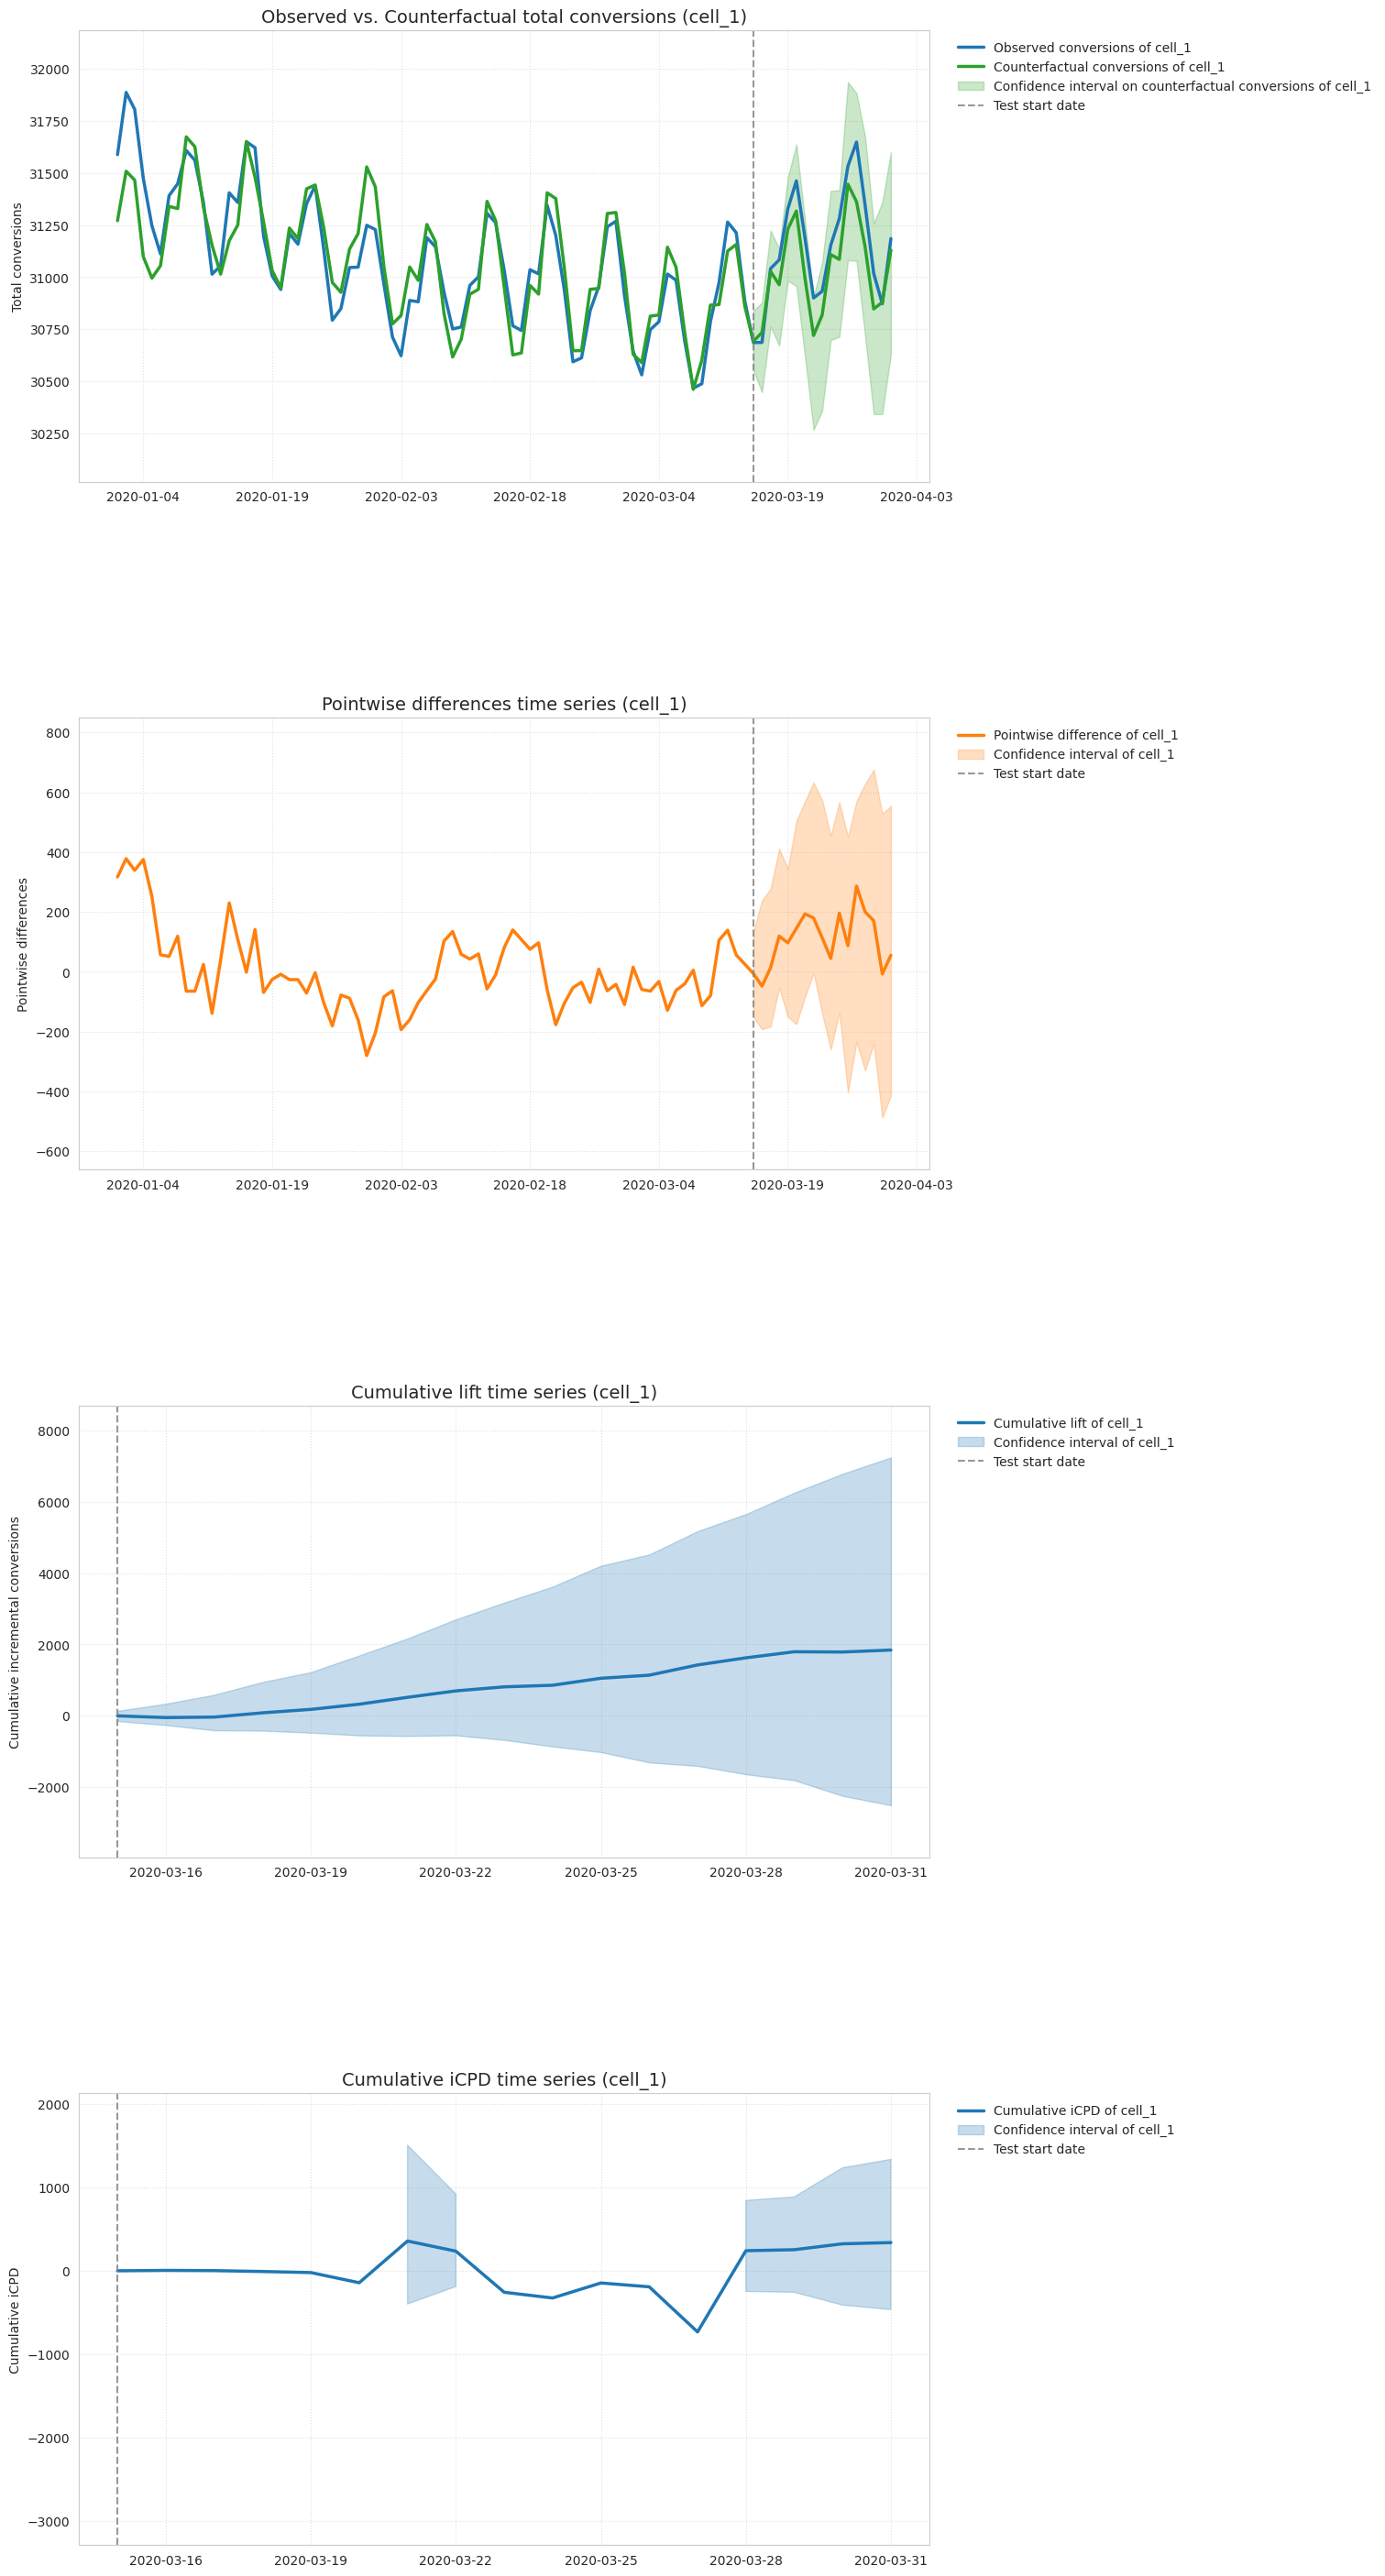

In [ ]:
#@title plot causal impact
import matplotlib.pyplot as plt

# Generate the GeoX standard multi-panel impact plot
fig = geox.plot_analysis(analysis_result)

# Display the plot
plt.show()

# Prior Design Evaluation

In [ ]:
#@title design backtest vs. results
import pandas as pd

# 1. Extract the top-ranked design object using the dictionary's first UUID key
top_uuid = list(design_set.designs.keys())[0]
top_design_obj = design_set.designs[top_uuid]

# 2. Extract the PerCellDesign object for cell_1
cell_1_design = top_design_obj.designs['cell_1']

# 3. Pull out the exact design artifacts
mde_pct = cell_1_design.minimum_detectable_effect  # Relative MDE (e.g., 0.0278 -> 2.78%)
implied_cpic = cell_1_design.design_implied_cpic   # Implied Cost per Incremental Conversion ($1,292.48)
aa_p_value = cell_1_design.p_value                 # Placebo A/A p-value (0.431)
simulated_budget = cell_1_design.budget            # Budget assigned to cell_1

# 4. Calculate Absolute MDE (Conversions)
# Multiply relative MDE by total pre-test conversions in treatment DMAs during test-equivalent duration
treatment_geos = cell_1_design.treatment_geos
pretest_tx_data = analysis_data[
    (analysis_data['date'] < experiment['analysis_start_date']) &
    (analysis_data['location'].isin(treatment_geos))
]
total_pretest_conversions = pretest_tx_data['conversions'].sum()
mde_abs = total_pretest_conversions * mde_pct

# 5. Display the Validation Scorecard
print("==================================================")
print("     PRE-TEST DESIGN VALIDATION SCORECARD         ")
print("==================================================")
print(f"Top Design UUID:                  {top_uuid}")
print(f"Pre-Test A/A Placebo p-value:     {aa_p_value:.3f}")
print(f"Minimum Detectable Effect (%):    {mde_pct:.2%}")
print(f"Minimum Detectable Effect (Abs):  ~{mde_abs:,.0f} conversions")
print(f"Design-Implied Cost/Driver:       ${implied_cpic:,.2f}")
print("--------------------------------------------------")

# Interpret A/A Test
if aa_p_value > 0.05:
    print("✓ PASS: Placebo p-value > 0.05 confirms treatment & control groups were well-balanced pre-test.")
else:
    print("⚠ WARNING: Placebo p-value <= 0.05 indicates potential pre-existing structural divergence.")

# 6. Compare against Actual Backtest Performance
actual_lift = cell_1_metrics.lift.point_estimate
actual_percent_lift = cell_1_metrics.percent_lift.point_estimate
alpha = 0.05
sig = p_value < alpha
exceeds_mde = abs(actual_percent_lift) >= mde_pct

print("\n==================================================")
print("     BACKTEST vs. DESIGN MDE (PLANNING BENCHMARK)  ")
print("==================================================")
print(f"Observed percent lift (point):  {actual_percent_lift:.2%}")
print(f"Design MDE (relative):          {mde_pct:.2%}")
print(f"Observed incremental lift:      {actual_lift:,.0f} conversions")
print(f"Design MDE (absolute, approx):  ~{mde_abs:,.0f} conversions")
print(f"Lift p-value:                   {p_value:.4f}  (significant at α={alpha}: {sig})")
print("--------------------------------------------------")
if exceeds_mde and sig:
    print(
        "✓ Observed lift is at or above the design MDE and statistically significant: "
        "the realized effect is large enough to meet the design benchmark and GeoX rejects a null effect."
    )
elif exceeds_mde and not sig:
    print(
        "◐ Observed lift meets or exceeds the design MDE, but the result is not statistically significant "
        f"(p={p_value:.3f} ≥ {alpha}). The point estimate is large, but uncertainty is wide (CI likely includes zero)."
    )
elif not exceeds_mde and sig:
    print(
        "◐ Statistically significant lift, but below the design MDE: "
        "you detected an effect, but it is smaller than the conservative MDE used in pre-test simulation "
        "(common when post-period variance is lower than assumed, or the true effect is modest but precise)."
    )
else:
    print(
        "⚠ Below design MDE and not statistically significant: "
        f"observed lift ({actual_percent_lift:.2%}) is under the design MDE ({mde_pct:.2%}) "
        f"and p={p_value:.3f} does not support a clear incremental effect at α={alpha}. "
        "Treat as inconclusive / null for decisioning unless you have other evidence."
    )

print(f"  |observed| >= MDE: {exceeds_mde}; significant: {sig}")

     PRE-TEST DESIGN VALIDATION SCORECARD         
Top Design UUID:                  2c6bfe5f-a2dd-45e6-ba6e-3c58839f0759
Pre-Test A/A Placebo p-value:     0.698
Minimum Detectable Effect (%):    1.33%
Minimum Detectable Effect (Abs):  ~17,935 conversions
Design-Implied Cost/Driver:       $0.89
--------------------------------------------------
✓ PASS: Placebo p-value > 0.05 confirms treatment & control groups were well-balanced pre-test.

     BACKTEST vs. DESIGN MDE (PLANNING BENCHMARK)  
Observed percent lift (point):  0.35%
Design MDE (relative):          1.33%
Observed incremental lift:      1,841 conversions
Design MDE (absolute, approx):  ~17,935 conversions
Lift p-value:                   0.4411  (significant at α=0.05: False)
--------------------------------------------------
⚠ Below design MDE and not statistically significant: observed lift (0.35%) is under the design MDE (1.33%) and p=0.441 does not support a clear incremental effect at α=0.05. Treat as inconclusive / null 

# Limitations

1. This is a workaround, not a supported “analysis-only” API

This notebook builds a synthetic Design / PerCellDesign so geox.analyze() will run. That is not the same as loading the original GeoX design file. Placeholder fields (MDE, A/A p-value, budget on the cell) satisfy the constructor; they do not restore historical design metadata unless you enter real values.

2. Treatment and control must be explicit and disjoint

The panel should be restricted to treatment_geos ∪ control_geos. Labeling “not in treatment ⇒ control” mis-assigns geos that should be excluded or held out. Overlapping or swapped geos break TBR balance assumptions.

3. One concurrent geo test per market (usually)

If a DMA was treated in another flight during pre-test or overlap, counterfactual fit and lift can be biased. Document exclusions or use a residual-control pool; GeoX does not infer overlap from spend alone.

4. `analysis_start_date` / `analysis_end_date` must match how the test was actually run

Status (Pre-test vs Live), AnalysisConfig, and stakeholder readouts all key off these dates. If launch, ramp, or read windows differ from “analysis start,” lift and efficiency will not match ops reality.

5. KPI definition is yours; GeoX only sees conversions

Orders, revenue, leads, etc. must be defined consistently in the panel. Mixing definitions across experiments makes cross-test tables incomparable.

6. Spend in the panel ≠ “campaign spend” for efficiency

TBR lift and p-values are driven by conversions, not spend. Panel spend (e.g. social campaign's geo spend) can inflate or distort GeoX iCPD / implied spend. Use actual flight spend for CPIC / corrected efficiency; keep campaign scorecard efficiency labeled as “panel-based” unless spend is flight-specific.

7. iCPD vs $/incremental conversion

GeoX iCPD = incremental conversions per dollar. $/incremental conversion (CPIC) is the reciprocal.

8. Stratified / multi-cell designs

geo_stratum_labels = np.ones(...) is only valid for a simple single-cell, unstratified backtest. Real stratified designs need correct stratum labels aligned to GeoX’s geo ordering.

9. Optional run_design on pre-period is retrospective, not validation of the original brief

Re-running design on pre-test data produces what GeoX would recommend now given your constraints—not proof that the field team followed that design. Compare MDE to observed lift as a planning benchmark, not as pass/fail of the original study unless you also have the real design artifact.

10. Design MDE vs statistical significance

Below design MDE does not always mean “no effect”; above MDE does not always mean significance. Always report point lift, CI, and p-value alongside MDE comparison.

11. Short live windows

Few post-launch days (e.g. live tests still running) yield unstable lift, wide CIs, and noisy design comparisons.

12. TBR proxy (sklearn) ≠ official GeoX TBR

Pre-test R²/RMSE/MAPE in the notebook is for intuition; official inference uses GeoX’s implementation.

13. Package version

ExperimentType, Methodology, and API shapes can change between meridian-geox releases; pin a version for reproducible backtests.

# FAQ

Q: Can I run post-experiment analysis without a GeoX design file?

A: Not as a first-class API today; this notebook reconstructs a minimal Design from geos + dates + type + methodology. See meridian-geox#13.


Q: What is the minimum I need?

A: Daily panel (date, location, conversions; optional spend), disjoint treatment_geos and control_geos, analysis window dates, ExperimentType, and Methodology (e.g. TBR for heavy-up with controls).

Q: Why does my “Corrected” efficiency disagree with the Campaign scorecard?

A: Campaign metrics use spend in the uploaded panel (often all geo ads). Corrected metrics should use actual media spend on the flight. Lift and p-value are usually unchanged; only efficiency lines move.

Q: What does “below MDE” mean if p is still high?

A: The point estimate is smaller than the design’s conservative detectability target and the result is not statistically significant—treat as inconclusive unless other evidence exists.

Q: What if p < 0.05 but lift is below MDE?

A: You detected a real but smaller-than-planned effect (or variance was lower than the design simulation assumed). Common in backtests; say both things explicitly.

Q: Can I backtest Spotify / YouTube / other channels the same way?

A: Same GeoX workflow; change KPI panel and actual flight spend for corrected efficiency. Channel does not change TBR lift math—only data prep and spend truth.

Q: Can I use DMA names instead of numeric geo IDs?

A: Yes, if location in the panel exactly matches the strings in your geo sets (same spelling, casing, and encoding as in your warehouse).

Q: When should I not use this notebook?

A: Holdback/go-dark mis-specified, no valid controls, heavy overlap with other geo tests, multi-cell/stratified designs without proper labels, or when you need official GeoX design provenance for audit/compliance.

Q: How does this relate to our internal diff-in-diff / experiment log pipeline?

A: GeoX is an alternate counterfactual (TBR, SDID) engine on a daily geo panel. Results will not match Welch diff-in-diff point estimates unless windows, KPI, and units align; use both as complementary checks, not as identical duplicates.